# Lepton-jet reconstruction efficiency: the DSA muons of prompt muons in data

The data part of [`09_dsa_prompt_muons.ipynb`](09_dsa_prompt_muons.ipynb): the fraction of prompt
muons that have a selected DSA muon (the lepton-jet source cuts of DSA muons without the
cross-cleaning: $p_T$ > 10 GeV, $|\eta|$ < 2.4, displaced ID, η-φ veto) in data, against the
simulation, for

- **single muons**, the $Z \to \mu\mu$ tag and probe;
- **two collimated muons**, the boosted $J/\psi \to \mu\mu$ pairs, a check at the level of lepton
  jets.

**Data.** Campaign `dsa_prompt_data_v1`: the unskimmed DoubleMuon ntuples of 2018C (636 files), the
alone versions only. The group approved this use (2026-11-24). The data are read only through
`systematics_study.lj_cr_data`, with the safety table of notebook 09 (section 5), which found every
region of both samples safe.

**Trigger.** The skimmed DoubleMuon ntuples keep only the events of the analysis triggers, which
need a standalone muon on both legs and raise the single-muon fraction by 3.3 points in simulation.
The tag and probe here uses Mu37_TkMu27, in data and simulation alike: its second leg needs only a
tracker muon, which raises the fraction by 0.6 points (notebook 09, section 3).

**Simulation.** Campaign `lj_reco_cr_v3`: Drell-Yan for the $Z$, every background for the $J/\psi$
(mostly QCD). The data cover 2018C only, so where yields are shown the simulation is normalized to
the data in the peak; the passing fractions do not depend on it.

In [1]:
import os, shutil, sys, tempfile, json, warnings
from pathlib import Path
import numpy as np
import hist
import matplotlib.pyplot as plt

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # on the path through systematics_study  # pylint: disable=import-error

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

DATA_DIR = sysstudy.eos_url(sysstudy.DSA_DATA_DIR)              # merged outputs of dsa_prompt_data_v1
SIM_DIR = sysstudy.eos_url(sysstudy.LJ_CR_V3_DIR)               # merged outputs of lj_reco_cr_v3
OUTPUT_DIR = sysstudy.eos_url(sysstudy.DSA_DATA_RESULTS_DIR)    # figures and passing fractions
if not sysstudy.list_coffea(DATA_DIR):
    raise FileNotFoundError(f"No merged outputs in {DATA_DIR} yet: run the campaign dsa_prompt_data_v1 "
                            "(condor/README.md, section 23)")
WORK = Path(tempfile.mkdtemp(prefix="dsa_prompt_data_"))   # removed at the end
Z, JPSI = "Z -> mumu, DSA", "J/psi -> mumu, DSA"
TRIGGER_AXES = ("trig_analysis", "trig_isomu24", "trig_tkmu")
Z_TRIGGER = "trig_tkmu"            # Mu37_TkMu27
JPSI_TRIGGER = "trig_analysis"     # the only trigger axis of the J/psi pairs
DY = sysstudy.LJ_CR_GROUPS[r"DY$\to\ell\ell$"]
TWO = ("n_dsa", (2,))              # J/psi pairs: both muons with their own DSA muon


def triggers(h):
    """The trigger axes h carries: all of TRIGGER_AXES for the Z, the analysis triggers only for
    the J/psi pairs (hists.dsa_jpsi_probe_hist)"""
    return [a.name for a in h.axes if a.name in TRIGGER_AXES]


def select(h, trigger, **extra):
    """The probes of h that fired one trigger (an axis of TRIGGER_AXES), its other trigger axes
    summed, with more slices in extra"""
    return h[{trigger: 1, **{k: sum for k in triggers(h) if k != trigger}, **extra}]


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


def label(axes):
    """The CMS label of a data figure; the data cover 2018C only, so no luminosity is quoted"""
    pt.cms_label(axes, data=True, text="Work in progress", lumi=None)


def ratio_text(d, s):
    """'r +- u' for the ratio of two (fraction, uncertainty, probes) results"""
    r = d[0] / s[0]
    return f"{r:.4f} +- {r * np.hypot(d[1] / d[0], s[1] / s[0]):.4f}"

## 1. Inputs, through the safety table

The safety table of notebook 09 is read back first (`lj_cr_verdicts`, which also checks the
sparse-bin rule it was judged with); `lj_cr_data` then reads the data, refusing any region the table
does not mark safe and setting such regions to zero. Below, per sample and trigger, the probes in the
peak and after the sideband subtraction, in data and in the simulation (Drell-Yan for the $Z$,
every background for the $J/\psi$).

In [2]:
rows = sysstudy.lj_cr_verdicts(sysstudy.DSA_RESULTS_DIR)
for cr in sysstudy.DSA_CR:
    print(f"{cr}: readable regions: {len(sysstudy.lj_cr_readable(rows, cr))}")
data = sysstudy.lj_cr_data(rows, DATA_DIR, specs=sysstudy.DSA_CR)
sim = sysstudy.lj_cr_inputs(SIM_DIR, specs=sysstudy.DSA_CR)
sim_total = {cr: sum(per[cr] for per in sim["background"].values()) for cr in sysstudy.DSA_CR}
sim_z = sum(sim["background"][s][Z] for s in DY if s in sim["background"])
sim_j = sim_total[JPSI]
print()
for cr, h_sim in ((Z, sim_z), (JPSI, sim_j)):
    spec = sysstudy.DSA_CR[cr]
    (lo, hi), sidebands = spec["peak"], spec["sidebands"]
    k = (hi - lo) / sum(b - a for a, b in sidebands)
    for trigger in triggers(data[cr]):
        for name, h in (("data", data[cr]), ("simulation", h_sim)):
            hh = select(h, trigger)
            peak = sysstudy.mass_window(hh, spec["mass"], lo, hi).sum(flow=True).value
            side = sum(sysstudy.mass_window(hh, spec["mass"], a, b).sum(flow=True).value for a, b in sidebands)
            print(f"{cr:20s} {trigger:14s} {name:10s}: {peak:11.4g} in the peak, "
                  f"{peak - k * side:11.4g} after the subtraction")

Z -> mumu, DSA: readable regions: 10
J/psi -> mumu, DSA: readable regions: 10



Z -> mumu, DSA       trig_analysis  data      :   5.642e+06 in the peak,   5.287e+06 after the subtraction
Z -> mumu, DSA       trig_analysis  simulation:   4.927e+07 in the peak,   4.635e+07 after the subtraction
Z -> mumu, DSA       trig_isomu24   data      :     7.1e+06 in the peak,   6.638e+06 after the subtraction
Z -> mumu, DSA       trig_isomu24   simulation:   5.984e+07 in the peak,   5.616e+07 after the subtraction
Z -> mumu, DSA       trig_tkmu      data      :   5.951e+06 in the peak,   5.607e+06 after the subtraction
Z -> mumu, DSA       trig_tkmu      simulation:    4.89e+07 in the peak,   4.625e+07 after the subtraction
J/psi -> mumu, DSA   trig_analysis  data      :   3.076e+05 in the peak,   2.507e+05 after the subtraction
J/psi -> mumu, DSA   trig_analysis  simulation:   2.208e+06 in the peak,   1.718e+06 after the subtraction


**Interpretation (run of 2026-11-24: `dsa_prompt_data_v1`, the 636 files of the unskimmed
DoubleMuon 2018C; simulation `lj_reco_cr_v3`).** Both samples are readable in full. With
Mu37_TkMu27 the data hold 5.6 million $Z \to \mu\mu$ probes after the sideband subtraction, and
between 5.3 and 6.6 million with the other two triggers. The $J/\psi$ pairs, which carry only the
decision of the analysis triggers, number 251,000 after the subtraction in data; their simulation
is QCD, with few effective events (5,600 for every trigger together, notebook 09).

## 2. The tag-and-probe mass

The mass of the tag and the probe with Mu37_TkMu27, and of the $J/\psi$ pairs with the trigger of
section 4: the data as points, the simulation stacked by process and normalized to the data in
the peak.

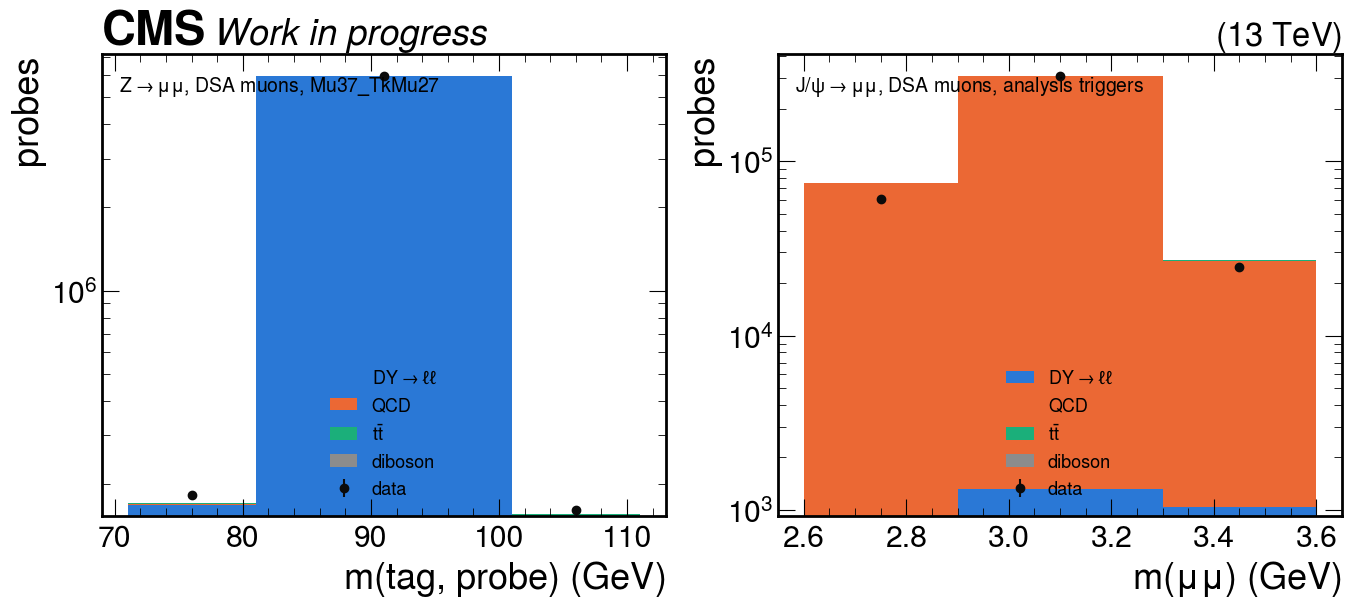

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cr, trigger in ((axes[0], Z, Z_TRIGGER), (axes[1], JPSI, JPSI_TRIGGER)):
    spec = sysstudy.DSA_CR[cr]
    sel = {trigger: 1, **{k: sum for k in triggers(data[cr]) if k != trigger}}
    lo, hi = spec["peak"]
    n_data = sysstudy.mass_window(data[cr][sel], spec["mass"], lo, hi).sum(flow=True).value
    n_sim = sysstudy.mass_window(sim_total[cr][sel], spec["mass"], lo, hi).sum(flow=True).value
    sysstudy.plot_mass_data_mc(data, sim, cr, sel=sel, ax=ax, specs=sysstudy.DSA_CR, scale=n_data / n_sim)
    ax.set_yscale("log")
    ax.legend(fontsize=13, loc="lower center")
    ax.text(0.03, 0.92, f"{spec['label']}, " + ("Mu37_TkMu27" if trigger == "trig_tkmu" else "analysis triggers"),
            transform=ax.transAxes, fontsize=14)
label(axes)
save(fig, "mass_data_simulation")
plt.show()

**Interpretation.** The $Z$ peak is nearly free of background in data as in the simulation: the
sidebands hold 6% of the peak in data and 5% in Drell-Yan. Under the $J/\psi$ peak the background
is a slightly smaller part of the data than of the simulation (sidebands of 28% and 33% of the
peak); the subtraction removes it in each.

## 3. Single muons: the Z → μμ tag and probe

The fraction of probes with a selected DSA muon within $\Delta R < 0.2$, with Mu37_TkMu27, in data and
in Drell-Yan simulation, against the probe's $p_T$ and $|\eta|$, with their ratio; then over all
probes and per region of the detector.

Z -> mumu, DSA, Mu37_TkMu27, against probe_pt:  data | Drell-Yan | data/Drell-Yan
   10-20: 0.6599 +- 0.0322 | 0.7962 +- 0.0212 | 0.8288 +- 0.0460
   20-30: 0.7228 +- 0.0012 | 0.8310 +- 0.0007 | 0.8697 +- 0.0016
   30-40: 0.7134 +- 0.0004 | 0.8232 +- 0.0002 | 0.8666 +- 0.0005
   40-50: 0.7031 +- 0.0003 | 0.8157 +- 0.0001 | 0.8619 +- 0.0004
   50-60: 0.6935 +- 0.0006 | 0.8082 +- 0.0004 | 0.8581 +- 0.0009
   60-80: 0.6826 +- 0.0011 | 0.8022 +- 0.0007 | 0.8508 +- 0.0016
   80-120: 0.6446 +- 0.0023 | 0.7767 +- 0.0014 | 0.8298 +- 0.0033
   120-200: 0.5929 +- 0.0042 | 0.7379 +- 0.0027 | 0.8035 +- 0.0064
Z -> mumu, DSA, Mu37_TkMu27, against probe_abseta:  data | Drell-Yan | data/Drell-Yan
   0-0.9: 0.7474 +- 0.0003 | 0.8552 +- 0.0001 | 0.8739 +- 0.0004
   0.9-1.2: 0.6567 +- 0.0006 | 0.7868 +- 0.0003 | 0.8347 +- 0.0008
   1.2-2.1: 0.7260 +- 0.0003 | 0.8329 +- 0.0002 | 0.8716 +- 0.0005
   2.1-2.4: 0.4276 +- 0.0008 | 0.5548 +- 0.0005 | 0.7708 +- 0.0017


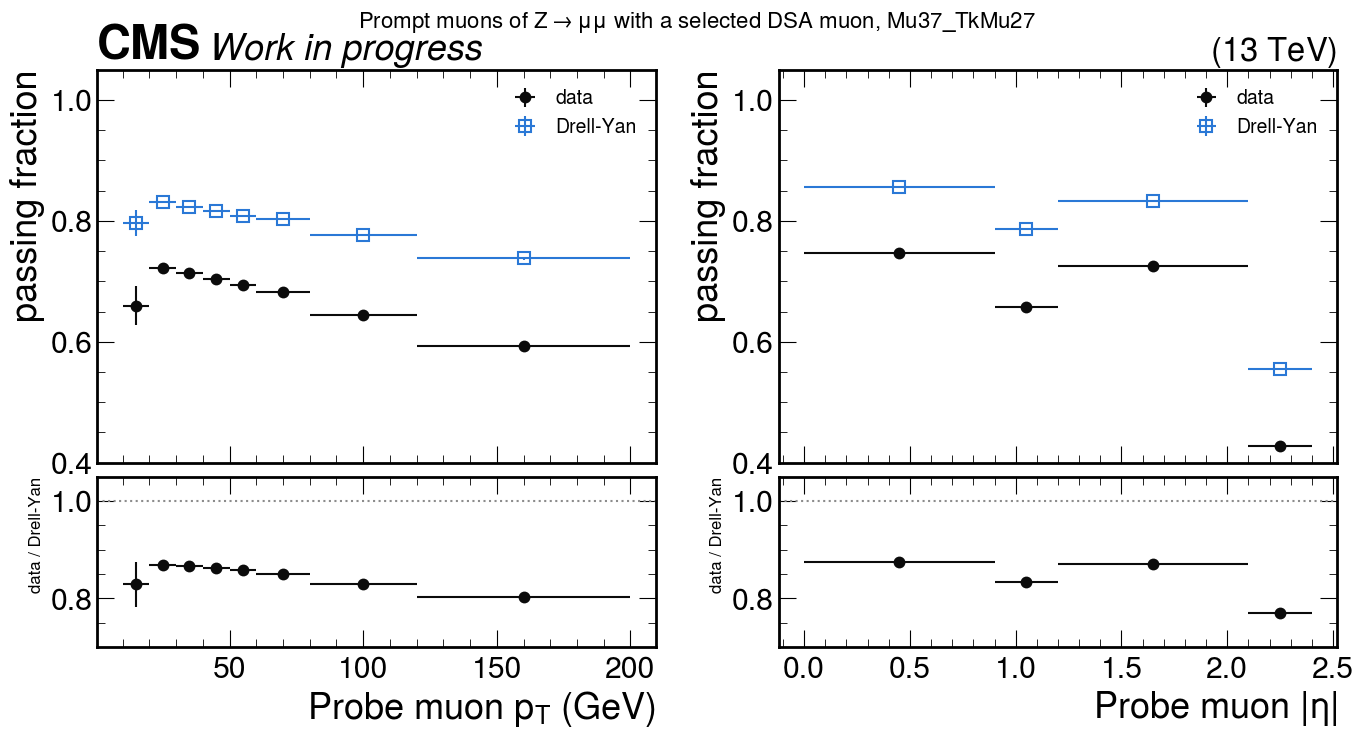


all probes            : data 0.7040 +- 0.0002 (5606638 probes), Drell-Yan 0.8167 +- 0.0001; data/Drell-Yan 0.8620 +- 0.0003
probe pT 30 to 60 GeV : data 0.7053 +- 0.0002 (5154169 probes), Drell-Yan 0.8173 +- 0.0001; data/Drell-Yan 0.8629 +- 0.0003
barrel, |eta| < 0.9   : data 0.7474 +- 0.0003 (2537985 probes), Drell-Yan 0.8552 +- 0.0001; data/Drell-Yan 0.8739 +- 0.0004
overlap, 0.9 to 1.2   : data 0.6567 +- 0.0006 (788127 probes), Drell-Yan 0.7868 +- 0.0003; data/Drell-Yan 0.8347 +- 0.0008
endcaps, 1.2 to 2.1   : data 0.7260 +- 0.0003 (1868056 probes), Drell-Yan 0.8329 +- 0.0002; data/Drell-Yan 0.8716 +- 0.0005
endcaps, 2.1 to 2.4   : data 0.4276 +- 0.0008 (412470 probes), Drell-Yan 0.5548 +- 0.0005; data/Drell-Yan 0.7708 +- 0.0017

trig_analysis  all probes   : data 0.7458 (5286634 probes), Drell-Yan 0.8437; data/Drell-Yan 0.8840 +- 0.0003
trig_analysis  tight probes : data 0.7514 (5220445 probes), Drell-Yan 0.8470; data/Drell-Yan 0.8872 +- 0.0003
trig_isomu24   all probes   : data 0

In [4]:
spec_z = sysstudy.DSA_CR[Z]
d_z = select(data[Z], Z_TRIGGER, probe_tight=sum)
s_z = select(sim_z, Z_TRIGGER, probe_tight=sum)
tables = {}
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05, "wspace": 0.22})
for col, axis in enumerate(("probe_pt", "probe_abseta")):
    results = {"data": sysstudy.probe_efficiency(d_z, spec_z, axis),
               "Drell-Yan": sysstudy.probe_efficiency(s_z, spec_z, axis)}
    sysstudy.plot_efficiency_comparison(results, "Drell-Yan", axes[0, col], axes[1, col])
    axes[0, col].set_ylim(0.4, 1.05)
    axes[1, col].set_ylim(0.7, 1.05)
    tables[(Z, axis)] = sysstudy.efficiency_table(results, "Drell-Yan")
    print(f"{Z}, Mu37_TkMu27, against {axis}:  data | Drell-Yan | data/Drell-Yan")
    for lo, hi, d, de, s, se, r, re in tables[(Z, axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.4f} +- {de:.4f} | {s:.4f} +- {se:.4f} | {r:.4f} +- {re:.4f}")
fig.suptitle(r"Prompt muons of $Z \to \mu\mu$ with a selected DSA muon, Mu37_TkMu27", fontsize=16, y=0.96)
label(axes[0])
save(fig, "dsa_z_data_simulation")
plt.show()
print()
for name, sel in (("all probes", {}),
                  ("probe pT 30 to 60 GeV", {"probe_pt": slice(hist.loc(30), hist.loc(60), sum)}),
                  ("barrel, |eta| < 0.9", {"probe_abseta": slice(None, hist.loc(0.9), sum)}),
                  ("overlap, 0.9 to 1.2", {"probe_abseta": slice(hist.loc(0.9), hist.loc(1.2), sum)}),
                  ("endcaps, 1.2 to 2.1", {"probe_abseta": slice(hist.loc(1.2), hist.loc(2.1), sum)}),
                  ("endcaps, 2.1 to 2.4", {"probe_abseta": slice(hist.loc(2.1), None, sum)})):
    d, s = (sysstudy.integrated_efficiency(h[sel] if sel else h, spec_z) for h in (d_z, s_z))
    print(f"{name:22s}: data {d[0]:.4f} +- {d[1]:.4f} ({d[2]:.0f} probes), Drell-Yan {s[0]:.4f} +- {s[1]:.4f}; "
          f"data/Drell-Yan {ratio_text(d, s)}")
print()
for trigger in TRIGGER_AXES:   # the ratio with each trigger, for every probe and for tight probes only
    for name, tight in (("all probes", sum), ("tight probes", 1)):
        d, s = (sysstudy.integrated_efficiency(select(h, trigger, probe_tight=tight), spec_z) for h in (data[Z], sim_z))
        print(f"{trigger:14s} {name:13s}: data {d[0]:.4f} ({d[2]:.0f} probes), Drell-Yan {s[0]:.4f}; "
              f"data/Drell-Yan {ratio_text(d, s)}")

**Interpretation.** With Mu37_TkMu27, 70.4% of the prompt muons have a selected DSA muon in data
and 81.7% in Drell-Yan simulation: a ratio of 0.862, with a statistical uncertainty of 0.0003. The
ratio is 0.87 from 20 to 60 GeV and falls to 0.80 above 120 GeV; it is 0.87 in the barrel and in
the endcaps up to $|\eta|$ = 2.1, 0.83 where barrel and endcaps overlap, and 0.77 above
$|\eta|$ = 2.1. It changes by at most 0.02 with the other triggers (0.88 with the analysis
triggers, 0.87 with IsoMu24) and for tight probes only (0.87), so it describes the DSA
reconstruction and selection, not the tag and probe; that spread is a measure of the uncertainty
of the method. The simulation overestimates the efficiency of DSA muons by about 14%.

## 4. Two collimated muons: J/ψ → μμ

The fraction of $J/\psi$ pairs whose two muons have their own selected DSA muon, against the pair's
$p_T$ and the separation of the muons, in data and in the background simulation. The histogram of
the pairs carries only the decision of the analysis triggers, so both are compared with them. They
need a standalone muon on both legs and raise this fraction by 0.14 to 0.23 in simulation (notebook
09, section 4); the comparison checks the simulation under that condition, which the signal
selection shares.

J/psi -> mumu, DSA, trig_analysis, two DSA muons, against probe_pt:  data | simulation | data/simulation
   20-30: 0.141 +- 0.002 | 0.161 +- 0.033 | 0.873 +- 0.179
   30-40: 0.335 +- 0.002 | 0.383 +- 0.033 | 0.873 +- 0.075
   40-50: 0.478 +- 0.003 | 0.594 +- 0.026 | 0.805 +- 0.035
   50-60: 0.527 +- 0.003 | 0.689 +- 0.019 | 0.765 +- 0.022
   60-80: 0.529 +- 0.003 | 0.704 +- 0.016 | 0.752 +- 0.017
   80-100: 0.496 +- 0.006 | 0.653 +- 0.018 | 0.760 +- 0.023
   100-150: 0.447 +- 0.008 | 0.651 +- 0.018 | 0.687 +- 0.023
   150-300: 0.348 +- 0.019 | 0.443 +- 0.078 | 0.786 +- 0.145
J/psi -> mumu, DSA, trig_analysis, two DSA muons, against probe_dR:  data | simulation | data/simulation
   0-0.01: nan +- nan | nan +- nan | nan +- nan
   0.01-0.02: -0.111 +- 0.155 | 0.133 +- 0.330 | -0.835 +- 2.375
   0.02-0.03: 0.237 +- 0.081 | 0.370 +- 0.080 | 0.641 +- 0.259
   0.03-0.05: 0.406 +- 0.017 | 0.562 +- 0.040 | 0.722 +- 0.060
   0.05-0.08: 0.497 +- 0.005 | 0.642 +- 0.017 | 0.774 +- 0.022
   0.08-0.1

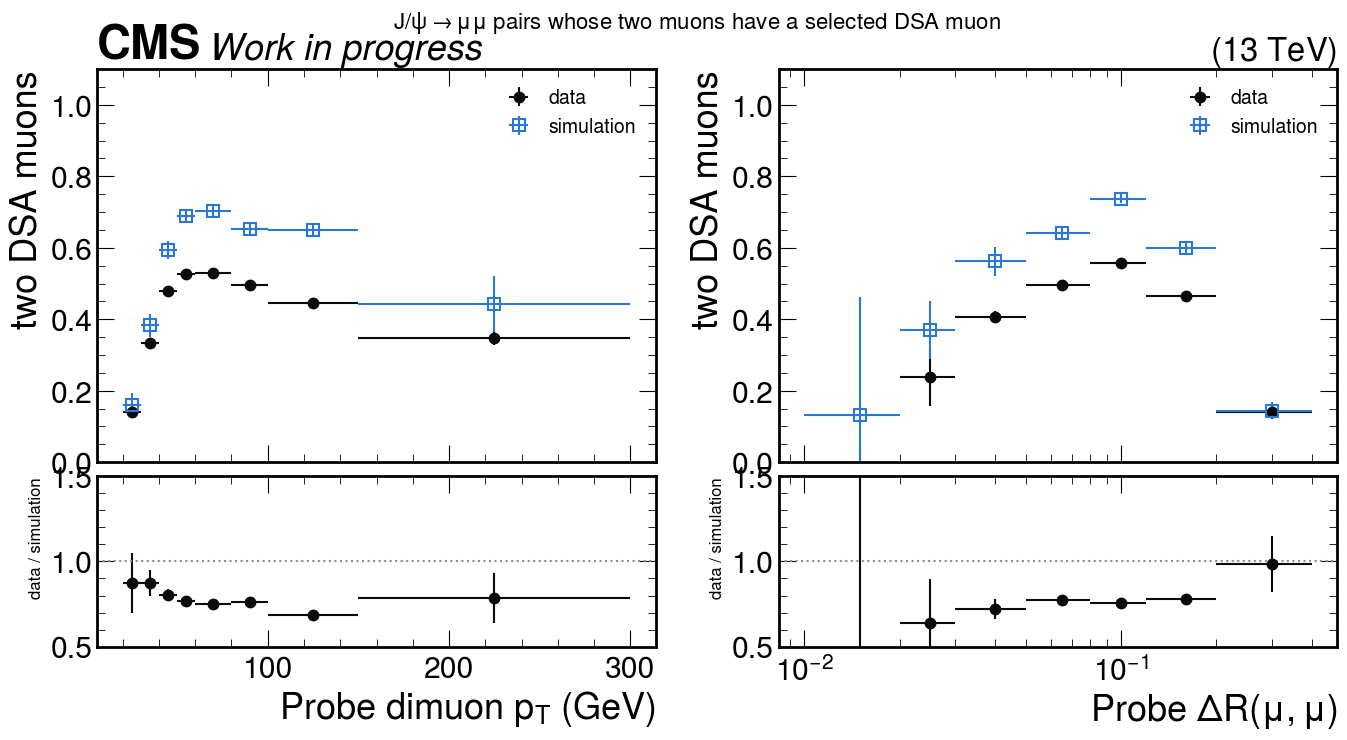


above 40 GeV, two DSA muons: data 0.503 +- 0.002 (143177 pairs), simulation 0.656 +- 0.011 (1106382); data/simulation 0.7665 +- 0.0127
above 40 GeV, at least one : data 0.892 +- 0.001 (143177 pairs), simulation 0.932 +- 0.005 (1106382); data/simulation 0.9561 +- 0.0056


In [5]:
spec_j = sysstudy.DSA_CR[JPSI]
d_j, s_j = select(data[JPSI], JPSI_TRIGGER), select(sim_j, JPSI_TRIGGER)
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05, "wspace": 0.22})
for col, axis in enumerate(("probe_pt", "probe_dR")):
    results = {"data": sysstudy.probe_efficiency(d_j, spec_j, axis, passing=TWO),
               "simulation": sysstudy.probe_efficiency(s_j, spec_j, axis, passing=TWO)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    axes[1, col].set_ylim(0.5, 1.5)
    tables[(JPSI, axis)] = sysstudy.efficiency_table(results, "simulation")
    print(f"{JPSI}, {JPSI_TRIGGER}, two DSA muons, against {axis}:  data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables[(JPSI, axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
axes[1, 1].set_xscale("log")
for ax in axes[0]:
    ax.set_ylabel("two DSA muons")
fig.suptitle(r"$J/\psi \to \mu\mu$ pairs whose two muons have a selected DSA muon", fontsize=16, y=0.96)
label(axes[0])
save(fig, "dsa_jpsi_data_simulation")
plt.show()
print()
above40 = {"probe_pt": slice(hist.loc(40), None, sum)}
for name, passing in (("two DSA muons", TWO), ("at least one", ("n_dsa", (1, 2)))):
    d, s = (sysstudy.integrated_efficiency(select(h, JPSI_TRIGGER, **above40), spec_j, passing)
            for h in (data[JPSI], sim_j))
    print(f"above 40 GeV, {name:13s}: data {d[0]:.3f} +- {d[1]:.3f} ({d[2]:.0f} pairs), "
          f"simulation {s[0]:.3f} +- {s[1]:.3f} ({s[2]:.0f}); data/simulation {ratio_text(d, s)}")

**Interpretation.** With the analysis triggers, both muons of a $J/\psi$ above 40 GeV have their
own selected DSA muon in 50.3% of the pairs in data and 65.6% in the simulation, a ratio of
0.77 ± 0.01; at least one of them has one in 89% and 93% (0.956 ± 0.006). The ratio is 0.69 to 0.81
from 40 to 300 GeV, and 0.72 to 0.78 for separations from 0.03 to 0.2; from 0.2 to 0.4, where the
pairs are soft and both muons are found in only 14%, it is 0.99 ± 0.17. The single-muon ratio with
the same triggers is 0.88 (section 3), and its square, 0.78, matches the pairs: within these
uncertainties each muon of a collimated pair carries the single-muon ratio.

## 5. What the comparison gives

- **Single DSA muons:** data/simulation 0.862 for prompt muons with Mu37_TkMu27, 0.80 to 0.87
  against $p_T$ and 0.77 to 0.87 against $|\eta|$, the same within 0.02 with the other triggers.
  The simulation overestimates the reconstruction and selection of DSA muons by about 14%, which
  a scale factor per DSA muon in bins of $p_T$ and $|\eta|$ corrects (section 6).
- **Two collimated DSA muons:** 0.77 ± 0.01 for $J/\psi$ pairs above 40 GeV with the analysis
  triggers, about the square of the single-muon ratio, so for separations from 0.03 to 0.4 the
  single-muon scale factor applied to each muon also describes the pairs.
- **Scope:** period C of 2018 only (unskimmed DoubleMuon ntuples are on EOS for period A and, in
  blocks, for period D); pairs
  closer than $\Delta R$ = 0.03 and DSA muons above 200 GeV are not reached (notebook 11).

## 6. The scale factor per DSA muon

The ratio of section 3 in the bins of probe $p_T$ and $|\eta|$ becomes the scale factor that the
corrections apply to every selected DSA muon of the simulation (`dsa_muon_id` in
`sidm/configs/corrections.yaml`, evaluated at the DSA muon's own $p_T$ and $|\eta|$). In each
$|\eta|$ bin, $p_T$ bins with fewer than 2,000 probes in data join their neighbours, so they take
the value of the nearest well-measured bins, and a DSA muon above 200 GeV takes the last bin (the
nearest populated bin). The uncertainty of each bin is its statistical one and, as a systematic,
the largest change of the scale factor with the analysis triggers, with IsoMu24, or for tight
probes. `systematics_study.write_dsa_correction` writes the correctionlib file into the repository
(`sidm/data/corrections/dsa_muon_sf_2018.json`), and a copy goes to EOS with the table.

In [6]:
dsa_sf = sysstudy.dsa_scale_factors(data[Z], sim_z, spec_z)
sf_path = sysstudy.write_dsa_correction(dsa_sf)    # into the repository
shutil.copy(sf_path, WORK / Path(sf_path).name)
print(f"written {sf_path}\n")
eta_edges, pt_edges = dsa_sf["abseta_edges"], dsa_sf["pt_edges"]
for i in range(len(eta_edges) - 1):
    print(f"|eta| {eta_edges[i]:g} to {eta_edges[i + 1]:g}")
    for j in range(len(pt_edges) - 1):
        alts = ", ".join(f"{label} {alt[i, j] - dsa_sf['sf'][i, j]:+.3f}"
                         for label, alt in dsa_sf["alternatives"].items())
        print(f"   {pt_edges[j]:g}-{pt_edges[j + 1]:g} GeV: {dsa_sf['sf'][i, j]:.3f} +- {dsa_sf['stat'][i, j]:.3f} (stat)"
              f" +- {dsa_sf['syst'][i, j]:.3f} (syst), {dsa_sf['probes'][i, j]:9.0f} data probes; {alts}")
with open(WORK / "dsa_scale_factor.json", "w") as f:
    json.dump({**{k: np.asarray(v).tolist() for k, v in dsa_sf.items() if k != "alternatives"},
               "alternatives": {k: v.tolist() for k, v in dsa_sf["alternatives"].items()}}, f, indent=1)

written /uscms_data/d3/scampbel/CMSSW_17_0_0_pre4/src/SIDM/sidm/data/corrections/dsa_muon_sf_2018.json

|eta| 0 to 0.9
   10-20 GeV: 0.889 +- 0.002 (stat) +- 0.028 (syst),     85693 data probes; analysis triggers +0.005, IsoMu24 +0.028, tight probes +0.004
   20-30 GeV: 0.889 +- 0.002 (stat) +- 0.028 (syst),     85693 data probes; analysis triggers +0.005, IsoMu24 +0.028, tight probes +0.004
   30-40 GeV: 0.880 +- 0.001 (stat) +- 0.014 (syst),    792029 data probes; analysis triggers +0.011, IsoMu24 +0.014, tight probes +0.004
   40-50 GeV: 0.873 +- 0.001 (stat) +- 0.010 (syst),   1275363 data probes; analysis triggers +0.010, IsoMu24 +0.010, tight probes +0.004
   50-60 GeV: 0.868 +- 0.001 (stat) +- 0.013 (syst),    261178 data probes; analysis triggers +0.009, IsoMu24 +0.013, tight probes +0.005
   60-80 GeV: 0.860 +- 0.002 (stat) +- 0.016 (syst),     90524 data probes; analysis triggers +0.008, IsoMu24 +0.016, tight probes +0.005
   80-120 GeV: 0.840 +- 0.004 (stat) +- 0.012 (syst),

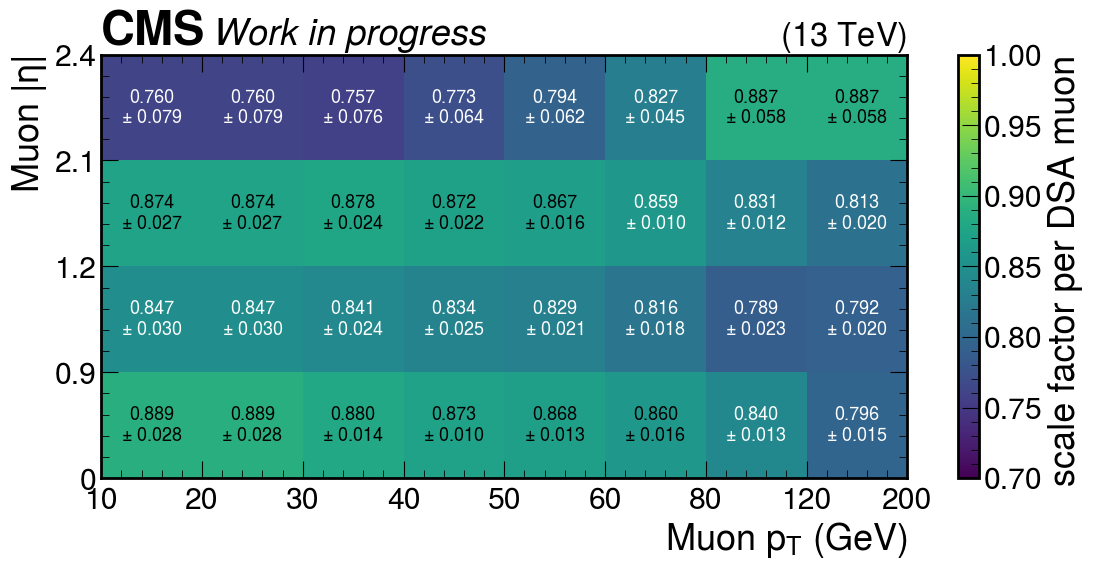

In [7]:
total = np.hypot(dsa_sf["stat"], dsa_sf["syst"])
fig, ax = plt.subplots(figsize=(13, 5.5))
mesh = ax.pcolormesh(np.arange(len(pt_edges)), np.arange(len(eta_edges)), dsa_sf["sf"],
                     cmap="viridis", vmin=0.7, vmax=1.0)
for i in range(len(eta_edges) - 1):
    for j in range(len(pt_edges) - 1):
        ax.text(j + 0.5, i + 0.5, f"{dsa_sf['sf'][i, j]:.3f}\n$\\pm$ {total[i, j]:.3f}", ha="center",
                va="center", fontsize=13, color="white" if dsa_sf["sf"][i, j] < 0.86 else "black")
ax.set_xticks(np.arange(len(pt_edges)), [f"{e:g}" for e in pt_edges])
ax.set_yticks(np.arange(len(eta_edges)), [f"{e:g}" for e in eta_edges])
ax.set_xlabel(r"Muon $p_T$ (GeV)")
ax.set_ylabel(r"Muon $|\eta|$")
fig.colorbar(mesh, ax=ax, label="scale factor per DSA muon")
label([ax])
save(fig, "dsa_scale_factor")
plt.show()

**Interpretation (run of 2026-11-24).** The scale factor per DSA muon is 0.80 to 0.89 in the
barrel and in the endcaps up to $|\eta|$ = 2.1, and it falls with $p_T$ in every region (in the
barrel from 0.889 below 30 GeV to 0.796 from 120 to 200 GeV); it is 0.79 to 0.85 where barrel and
endcaps overlap, and 0.76 to 0.89 above $|\eta|$ = 2.1. The statistical uncertainty is below 0.01
except in the highest $p_T$ bins (up to 0.025). The systematic uncertainty is 0.01 to 0.03 up to
$|\eta|$ = 2.1 and 0.05 to 0.08 above, set mostly by the analysis triggers: they need a standalone
muon on both legs, so they select probes that are more likely to have a DSA muon, more so in data
than in the simulation (in the barrel, IsoMu24 changes it by as much). Below 20 GeV, where
Mu37_TkMu27 leaves 52 to 171 probes per $|\eta|$ bin, and above 80 GeV for $|\eta|$ > 2.1, the bins
take the value of their merged neighbours. The probes above 200 GeV join the last bin, which every
DSA muon above 200 GeV takes.

In [8]:
with open(WORK / "passing_fractions.json", "w") as f:
    json.dump({" | ".join(key): [dict(zip(("low", "high", "data", "data_err", "simulation", "simulation_err",
                                         "ratio", "ratio_err"), map(float, row))) for row in table]
               for key, table in tables.items()}, f, indent=1)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/dsa_prompt_data_v1_results
